# 01 · 数据入口、审计与划分


本页以读取已保存产物和展示结果为主，不会因为展示而自动重训正式模型。

没有本地逐行数据时，Notebook 会读取 reports/published/ 中的聚合快照。

## 字段与分析边界

- f0–f11：12 个匿名处理前特征，是唯一模型输入。
- treatment：处理分配 T；不等于实际广告曝光。
- conversion / visit：两个结果指标 Y。
- exposure：实际曝光情况，只用于审计，不能加入 X 或据此筛选。

公开数据经过发布处理，项目结论针对公开样本的处理分配效果。匿名字段没有业务语义，不能据此编造用户画像。

In [19]:
from pathlib import Path
import sys, json, os

ROOT = next(  
    p 
    for p in (Path.cwd(), *Path.cwd().parents) 
    if (p / 'criteo_uplift').is_dir()
)

if str(ROOT) not in sys.path: 
    sys.path.insert(0, str(ROOT))

from criteo_uplift.runtime import configure_runtime
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from criteo_uplift.pipeline_io import result_directory

configure_runtime()

RUN = result_directory('conversion_1000000_seed42', ROOT) #RUN:结果目录 
print('读取结果目录:', RUN.relative_to(ROOT))
manifest = json.loads(((RUN / 'manifest.json')).read_text())
print('分析对象:', manifest['primary_outcome'], '| 随机样本:', f"{manifest['sample_n']:,}")
print('seed:', manifest['seed'], '| 主预算:', manifest['selection']['primary_budget'])

raw_path = ROOT / "data" / "raw" / "criteo-uplift-v2.1.csv"
if raw_path.is_file():
    display(pd.read_csv(raw_path, nrows=10))
else:
    print("本地未提供原始 Criteo CSV；当前只展示已发布的聚合结果，不影响 Notebook 读取。")
    print("预期字段：", [*manifest.get("features", []), "treatment", "conversion", "visit", "exposure"])




读取结果目录: artifacts/conversion_1000000_seed42
分析对象: conversion | 随机样本: 1,000,000
seed: 42 | 主预算: 0.2


,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9,f10,f11,treatment,conversion,visit,exposure
0,12.616365,10.059654,8.976429,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
1,12.616365,10.059654,9.002689,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
2,12.616365,10.059654,8.964775,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
3,12.616365,10.059654,9.002801,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
4,12.616365,10.059654,9.037999,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
5,12.616365,10.059654,8.904507,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
6,12.616365,10.059654,8.783340,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
7,12.616365,10.059654,8.964528,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
8,12.616365,10.059654,9.037809,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0
9,12.616365,10.059654,9.015128,4.679882,10.280525,4.115453,0.294443,4.833815,3.955396,13.190056,5.300375,-0.168679,1,0,0,0


## 全量扫描、审计与抽样

当前公开来源约 13,979,592 行。扫描按块读取原始 CSV，统一完成数据校验、全量审计统计、建模样本抽样以及诊断所需的统计和 C2ST 样本准备。

### 全量审计
- 全量内部重复：统计全量原始 float64 数据中全部 16 个字段的重复行指纹所对应的多余行数。只作为审计证据，不因匿名特征相同而自动删除，因为公开数据没有真实用户 ID。

### 抽样
 建模样本默认是 100 万行，使用随机优先级蓄水池抽样方法达到无放回随机抽样。
  
C2ST 样本准备默认20万行，从全量样本中按照treatment分层 50:50 抽样：
- C2ST 的目标不是训练最终的 uplift 模型，而是检验处理组和对照组的处理前特征分布是否存在可被分类器识别的差异；
- 因此，构造一个 50:50 的诊断样本，可以避免类别数量差异影响分类器训练和结果解释。例如，原始数据为 85:15 时，分类器即使始终预测多数类，也能获得 85% 的准确率，容易造成误解；少数类样本较少也会限制分类器对该组特征的学习。两组等量抽样可以消除多数类数量优势，使比较更直观。 对本项目使用的 ROC-AUC 而言，类别不平衡不会直接改变随机分类器的 0.5 基准，但两组样本量不等会影响估计精度。


### 其他说明

- 审计使用原始 float64；模型缓存使用 float32 降低内存。


In [2]:
# Notebook 只读取已保存的统计量，选择条目、翻译名称并格式化展示。
audit = json.loads((RUN / 'data_preparation' / 'audit.json').read_text())
sample_report = json.loads((RUN / 'data_preparation' / 'sample_report.json').read_text())

# 1. 样本构成与转化：组内和总体的行数、比例、转化数、转化率均已在 JSON 中生成。
group_columns = {'group': '组别', 'n': '样本行数', 'fraction': '样本占比',
                 'conversion_positive': '转化行数', 'conversion_rate': '组内转化率'}
for title, report in (('全量数据：样本构成与转化', audit), ('建模样本：样本构成与转化', sample_report)):
    display(HTML(f'<h4>{title}</h4>'))
    table = pd.DataFrame(report['group_summary'])[list(group_columns)].rename(columns=group_columns)
    table['组别'] = table['组别'].replace({'Control': '对照组', 'Treatment': '处理组'})
    display(table.style.hide(axis='index').format({
        '样本行数': '{:,.0f}', '转化行数': '{:,.0f}',
        '样本占比': '{:.4%}', '组内转化率': '{:.4%}',
    }, na_rep='—'))
print('按数据行计数，不代表去重用户数。样本占比以该表总行数为分母，组内转化率以对应组行数为分母。')

# 2. 基础质量检查：仅选择与此板块相关的审计字段，以中文展示。
display(HTML('<h4>全量数据：基础质量检查</h4>'))
quality_fields = {
    'n_columns': '原始字段数',
    'missing_or_nonfinite': '缺失或非有限值数',
    'invalid_binary_labels': '非法二元标签值数',
    'control_exposed': '对照组出现曝光的行数',
    'conversion_without_visit': '转化但无访问的行数',
}
display(pd.DataFrame([
    {'检查项目': title, '记录值': audit[key]} for key, title in quality_fields.items()
]).style.hide(axis='index').format({'记录值': '{:,.0f}'}))

# 3. 重复指纹单独说明，不能把匿名完整记录相同直接判为数据错误。
display(HTML('<h4>全量数据：重复记录候选</h4>'))
display(pd.DataFrame([{'检查项目': '完整记录重复指纹的多余行数',
                       '记录值': audit['duplicate_row_fingerprints']}])
        .style.hide(axis='index').format({'记录值': '{:,.0f}'}))
print('基于全部原始字段的 float64 表示计算 64 位行哈希；仅作诊断，不代表同一用户，不自动去重。')

# 4. 特征平衡只展示已有的 SMD，保持特征顺序，不在 Notebook 中重算统计量。
display(HTML('<h4>全量数据：特征平衡</h4>'))
smd_df = pd.DataFrame(audit['feature_stats'])[['feature', 'smd']].rename(
    columns={'feature': '特征', 'smd': '标准化均值差（SMD）'}
)
display(smd_df.style.hide(axis='index').format({'标准化均值差（SMD）': '{:+.6f}'}))


组别,样本行数,样本占比,转化行数,组内转化率
对照组,"2,096,937",15.0000%,"4,063",0.1938%
处理组,"11,882,655",85.0000%,"36,711",0.3089%
总体,"13,979,592",100.0000%,"40,774",0.2917%


组别,样本行数,样本占比,转化行数,组内转化率
对照组,"149,589",14.9589%,273,0.1825%
处理组,"850,411",85.0411%,"2,609",0.3068%
总体,"1,000,000",100.0000%,"2,882",0.2882%


按数据行计数，不代表去重用户数。样本占比以该表总行数为分母，组内转化率以对应组行数为分母。


检查项目,记录值
原始字段数,16
缺失或非有限值数,0
非法二元标签值数,0
对照组出现曝光的行数,0
转化但无访问的行数,0


检查项目,记录值
完整记录重复指纹的多余行数,"1,259,545"


基于全部原始字段的 float64 表示计算 64 位行哈希；仅作诊断，不代表同一用户，不自动去重。


特征,标准化均值差（SMD）
f0,-0.006866
f1,+0.023994
f2,-0.006241
f3,-0.048836
f4,+0.007966
f5,-0.030557
f6,-0.040448
f7,+0.021270
f8,-0.022433
f9,+0.024001


In [3]:
# 抽样配置与来源规模单独展示；分组统计已经在前面的表格中展示。
sample_fields = {'source_n': '来源数据总行数', 'sample_size': '请求抽样行数（0 表示全量）',
                 'sample_n': '实际建模样本行数', 'seed': '随机种子',
                 'sampling': '抽样方法', 'feature_representation': '建模特征精度',
                 'sample_cache_version': '抽样缓存格式版本'}
sample_report_df = pd.DataFrame([
    {'说明项目': title, '记录值': sample_report[key]} for key, title in sample_fields.items()
])
sample_report_df['记录值'] = sample_report_df['记录值'].replace({
    'uniform without replacement, random-priority reservoir': '均匀无放回抽样（随机优先级蓄水池）',
    'all rows': '保留全量样本',
})
display(sample_report_df.style.hide(axis='index'))


说明项目,记录值
来源数据总行数,13979592
请求抽样行数（0 表示全量）,1000000
实际建模样本行数,1000000
随机种子,42
抽样方法,均匀无放回抽样（随机优先级蓄水池）
建模特征精度,float32
抽样缓存格式版本,1


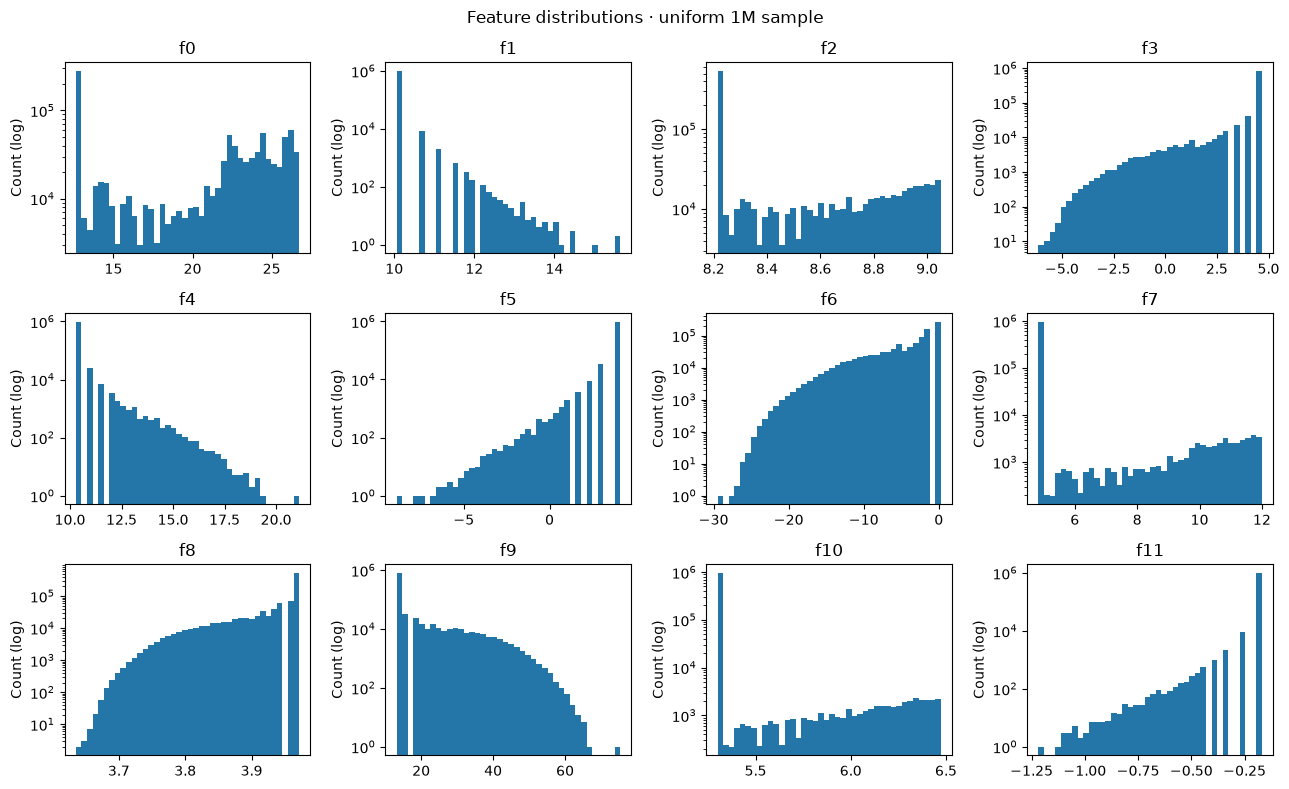

In [4]:
import matplotlib.pyplot as plt
from criteo_uplift.data import FEATURES
from criteo_uplift.pipeline_io import load_sample

# 逐行样本仅供下方特征分布图使用，不再展示样本明细表。
cache_path = ROOT / f"artifacts/cache/sample_{sample_report['sample_size']}_seed{sample_report['seed']}.npz"
sample = load_sample(cache_path) if cache_path.exists() and os.environ.get('CRITEO_RESULTS_MODE') != 'published' else None

# 12个特征分布可视化

if sample is None:
    display(Image(filename=str(RUN/'figures/sample_features.png')))
else:
    fig, axes = plt.subplots(3,4,figsize=(13,8))
    for feature, ax in zip(FEATURES,axes.flat):
        ax.hist(sample[feature],bins=40,color='#2476a8',log=True) #特征值的取值范围划分为40个区间，纵轴取对数（压缩数量级差异）
        ax.set_title(feature); ax.set_ylabel('Count (log)')
    fig.suptitle('Feature distributions · uniform 1M sample')
    fig.tight_layout(); plt.show()

## 数据划分与跨集合重复核验

### 数据划分

主实验对 100 万行建模样本采用 60% / 20% / 20% 的 Train / Validation / Test 划分，并按 `treatment × conversion` 联合分层：尽可能保持处理组与对照组的比例，以及两组各自的转化事件构成，减少随机切分带来的样本构成波动，使模型训练与独立评价更加稳定。

- 第一，Criteo 数据存在处理组与对照组比例不均衡的问题，同时转化事件比较稀少；
- 第二，uplift modeling 需要分别利用处理组和对照组的数据来学习和评价增量效果，因此不仅要关注整体转化率，还要关注两组各自的转化事件数量。


### 跨集合重复与精度核验

- **行级划分：** 检查各集合内部 `row_id` 唯一、集合之间无行号交集，且并集覆盖完整的 100 万行建模样本。
- **内容重复：** 比较原始 `float64` 特征、实际使用的 `float32` 建模特征，以及原始 16 个字段的完整记录，区分原始内容重复与数值精度舍入造成的新增匹配。
- **关键结果：** Train → Test 中，原始 `float64` 特征匹配（特征字段）为 2,658 行（1.329%），`float32` 建模特征匹配为 3,712 行（1.856%），原始完整记录匹配（全部16个字段）为 1,943 行（0.972%）。

相同匿名特征不等于同一用户，行号互斥也不等于用户级独立。由于缺少可靠的用户、事件标识和时间信息，无法仅凭这些检查确认真实用户层面的泄漏。

跨集合重复的隔离敏感性分析及其对模型评价的影响见 Notebook 06。

In [23]:
split_summary = pd.read_csv((RUN / 'data_preparation' / 'split_summary.csv'))
display(split_summary)

overlap = json.loads(((RUN / 'data_preparation' / 'feature_overlap.json')).read_text())
overlap_table = pd.DataFrame([
    {'split': split, 'fraction_matching_training_features': fraction}
    for split, fraction in overlap['fraction_matching_training_features'].items()
])
display(overlap_table.style.format({'fraction_matching_training_features': '{:.2%}'}))
del sample

,split,treatment,n,conversion_positive,visit_positive
0,train,0,89754,164,3372
1,train,1,510246,1565,24685
2,validation,0,29917,54,1064
3,validation,1,170083,522,8310
4,test,0,29918,55,1113
5,test,1,170082,522,8324


,split,fraction_matching_training_features
0,validation,1.86%
1,test,1.86%


## 如何复现与刷新结果

查看所有入口参数：在项目根目录运行 python run_pipeline.py --help。

运行新的开发实验时请指定一个新的输出目录，避免覆盖或混合正式产物：

~~~bash
python run_pipeline.py --sample-size 1000000 --outcome conversion --output artifacts/conversion_repeat
~~~

只想看已有结果时，不需要重跑主 Pipeline；默认 Notebook 会读取公开快照。若编辑了展示代码，使用 python scripts/execute_notebooks.py 刷新 Notebook 输出；需要优先读取本地 artifacts 时，添加 --local-results。

数据来源、运行路径与缓存说明见 ../docs/PROJECT_PIPELINE.md；产物解释见 ../docs/RESULTS_GUIDE.md。

In [24]:
display({
    'source': manifest['source'], 
    'versions': manifest['versions'], 
    'features': manifest['features']
})

{'source': {'path': '/Users/tk/Desktop/Criteo-uplift-project/data/raw/criteo-uplift-v2.1.csv',
  'size': 3248115221,
  'mtime_ns': 1790004809431929026,
  'sha256': 'e4d7c710ca1f38e523309d0f8a0745d1b53e7392d51f20d1088b6cfeaef222ef'},
 'versions': {'numpy': '2.4.6',
  'pandas': '3.0.5',
  'scipy': '1.17.1',
  'scikit-learn': '1.9.1',
  'xgboost': '3.2.0',
  'matplotlib': '3.11.1',
  'joblib': '1.6.0'},
 'features': ['f0',
  'f1',
  'f2',
  'f3',
  'f4',
  'f5',
  'f6',
  'f7',
  'f8',
  'f9',
  'f10',
  'f11']}